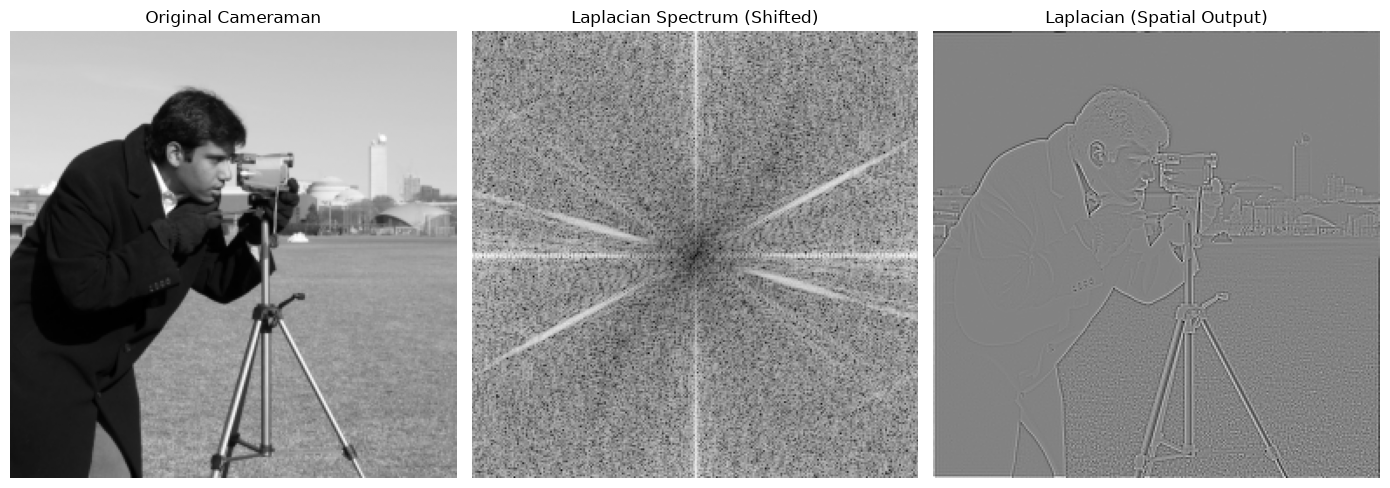

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize


image = data.camera()
image = resize(image, (256, 256))

M, N = image.shape


u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)


laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)


F = np.fft.fft2(image)


F_lap = F * laplacian_filter


laplacian_image = np.fft.ifft2(F_lap).real


plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(np.fft.fftshift(F_lap))), cmap='gray')
plt.title('Laplacian Spectrum (Shifted)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.show()

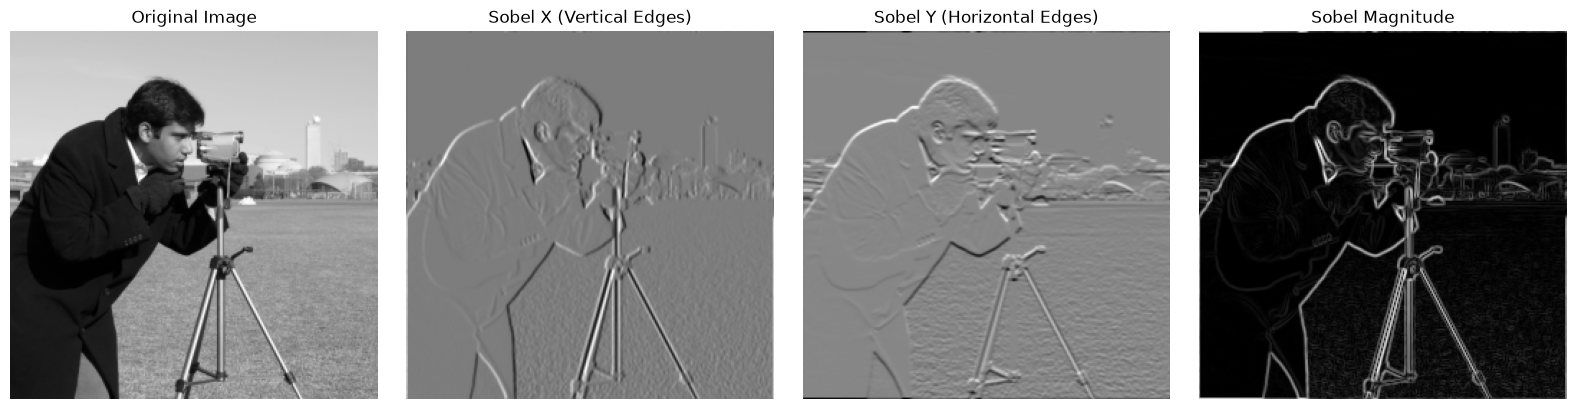

In [2]:
from numpy.fft import fft2, ifft2, ifftshift, fftshift


sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    cy, cx = ph // 2, pw // 2
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))


F_img = fft2(image)

H_sobel_x = center_embed_kernel(sobel_x, image.shape)
H_sobel_y = center_embed_kernel(sobel_y, image.shape)


G_x_freq = F_img * H_sobel_x
G_y_freq = F_img * H_sobel_y


edge_x = ifft2(G_x_freq).real
edge_y = ifft2(G_y_freq).real


edge_magnitude = np.hypot(edge_x, edge_y)


fig, ax = plt.subplots(1, 4, figsize=(16, 4))

ax[0].imshow(image, cmap='gray')
ax[0].set_title('Original Image')
ax[0].axis('off')

ax[1].imshow(edge_x, cmap='gray')
ax[1].set_title('Sobel X (Vertical Edges)')
ax[1].axis('off')

ax[2].imshow(edge_y, cmap='gray')
ax[2].set_title('Sobel Y (Horizontal Edges)')
ax[2].axis('off')

ax[3].imshow(edge_magnitude, cmap='gray')
ax[3].set_title('Sobel Magnitude')
ax[3].axis('off')

plt.tight_layout()
plt.show()